[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SEU_USUARIO/SEU_REPOSITORIO/blob/main/Bootcamp_DIO_BruteForce_PurpleTeam_Colab.ipynb)


# 🛡️ Simulando Ataques de Brute Force e Defesas Ativas (Medusa & Python no Google Colab)

Projeto prático desenvolvido para o **Bootcamp de Cibersegurança 2026 da DIO** (inspirado nas aulas da Profa. Dra. Isadora Ferrão).

> ⚠️ **Disclaimer Ético:** Todos os experimentos documentados neste repositório foram executados em ambiente de laboratório 100% isolado e controlado, com finalidade estritamente educacional e defensiva.

## 🎯 Objetivos do Projeto
- Compreender as diferenças arquiteturais entre autenticações **Stateless**, **Stateful** e **Federada (OAuth 2.0 / SAML)**.
- Analisar e comparar o ecossistema de ferramentas de auditoria de senhas do Kali Linux (**Medusa, Hydra, Ncrack, John the Ripper, WPScan e Patator**).
- Simular ataques de **Força Bruta em FTP**, **Automação de Formulário Web (DVWA)** e **Ataque em Cadeia (Enumeração SMB + Password Spraying)**.
- Implementar controles defensivos práticos (**Account Lockout / Rate Limiting** e auditoria de logs) demonstrando como neutralizar ofensivas automatizadas.

## 🧰 Ferramentas e Tecnologias Utilizadas
- **Ambiente de Execução:** Google Colab (Container Linux Ubuntu) & Kali Linux / Metasploitable 2
- **Linguagem e Bibliotecas:** Python 3 (`requests`, `concurrent.futures`, `http.server`, `pandas`, `matplotlib`)
- **Utilitários de Referência:** Medusa, Nmap, SMBClient
- **Copiloto de Arquitetura e Código:** Google Gemini

## 🗂️ Estrutura do Repositório
├── Bootcamp_DIO_BruteForce_PurpleTeam_Colab.ipynb  # Notebook executável completo
├── wordlists/
│   ├── users.txt                                   # Lista de usuários auditados
│   └── pass.txt                                    # Dicionário de senhas comuns
├── images/                                         # Evidências de execução e gráficos Blue Team
└── README.md                                       # Documentação técnica do projeto

## 🚀 Resumo dos Cenários Auditados e Mitigações Propostas

| Vetor / Serviço | Técnica Empregada | Descoberta no Lab | Medida de Mitigação Recomendada |
| :--- | :--- | :--- | :--- |
| **FTP (Porta 21)** | Brute Force Multithread (`-M ftp -t 6`) | Credencial padrão `msfadmin:msfadmin` exposta em texto claro | Desativar FTP legado, migrar para **SFTP/SCP** com chaves SSH e aplicar bloqueio via Fail2Ban. |
| **Web Login (DVWA)** | Automação HTTP POST com filtro `DENY-SIGNAL:"login failed"` | Acesso administrativo (`admin:password`) sem restrição de tentativas | Implementar **MFA**, **CAPTCHA**, tokens **CSRF** e *Rate Limiting* por IP/Sessão. |
| **SMB / Samba** | Enumeração de Contas + **Password Spraying** | Descoberta de contas corporativas e acesso via senha sazonal (`empresa2025`) | Desabilitar enumeração anônima (Null Sessions), segmentar a rede (VLAN/Firewall) e exigir políticas de senhas complexas sem padrões sazonais. |

## 📈 Como Executar no Google Colab
1. Clique no botão **Open in Colab** no topo deste README.
2. No menu superior do Colab, selecione **Ambiente de execução > Executar tudo (Run all)**.
3. Acompanhe a criação das *wordlists*, a subida do servidor vulnerável local, os logs de captura de credenciais e o gráfico final de bloqueio pelo módulo defensivo.



Setup do Ambiente e Instalação Opcional do Medusa


In [3]:


# ==============================================================================
# CÉLULA 1: CONFIGURAÇÃO DO AMBIENTE NO GOOGLE COLAB
# ==============================================================================
import os
import time
import json
import queue
import socket
import base64
import threading
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor, as_completed
from http.server import HTTPServer, BaseHTTPRequestHandler
from urllib.parse import parse_qs

import requests
import pandas as pd
import matplotlib.pyplot as plt

# Opcional: Descomente as duas linhas abaixo caso queira instalar o binário real
# do Medusa diretamente no container Ubuntu do Google Colab:
# !apt-get update -qq && apt-get install -y -qq medusa
# !medusa -V

print("[+] Ambiente Python configurado com sucesso para o Laboratório de Cibersegurança!")

[+] Ambiente Python configurado com sucesso para o Laboratório de Cibersegurança!


 **Criação das Wordlists** (users.txt, pass.txt) e Ataque Híbrido

In [4]:
# ==============================================================================
# CÉLULA 2: CRIAÇÃO DE WORDLISTS E VARIAÇÕES HÍBRIDAS (MANGLING RULES)
# ==============================================================================

# 1. Recriando exatamente os arquivos users.txt e pass.txt da aula prática
usuarios_base = ["user", "msfadmin", "admin", "root", "isa", "suporte", "financeiro"]
senhas_base = ["1234", "123456", "password", "kurt", "msfadmin", "empresa2025"]

with open("users.txt", "w") as f_users:
    f_users.write("\n".join(usuarios_base) + "\n")

with open("pass.txt", "w") as f_pass:
    f_pass.write("\n".join(senhas_base) + "\n")

print("[+] Arquivos 'users.txt' e 'pass.txt' gravados no diretório local do Colab.")

# 2. Demonstração de Mangling Rules (Ataque Híbrido: Dicionário + Mutação)
def gerar_variacoes_hibridas(palavra_base: str) -> list:
    """Aplica substituições comuns (leet speak) e sufixos temporais."""
    mapa_leet = str.maketrans({"a": "@", "e": "3", "i": "1", "o": "0", "s": "$"})
    palavra_leet = palavra_base.translate(mapa_leet)
    sufixos = ["2025", "2026", "!", "123"]

    variacoes = {palavra_base, palavra_base.capitalize(), palavra_leet}
    for s in sufixos:
        variacoes.add(f"{palavra_base}{s}")
        variacoes.add(f"{palavra_base.capitalize()}{s}")
        variacoes.add(f"{palavra_leet}{s}")
    return sorted(variacoes)

amostra_hibrida = gerar_variacoes_hibridas("senha")
print(f"[+] Exemplo de Mangling Rules para 'senha' ({len(amostra_hibrida)} variações):")
print("    ", amostra_hibrida[:8])


[+] Arquivos 'users.txt' e 'pass.txt' gravados no diretório local do Colab.
[+] Exemplo de Mangling Rules para 'senha' (15 variações):
     ['$3nh@', '$3nh@!', '$3nh@123', '$3nh@2025', '$3nh@2026', 'Senha', 'Senha!', 'Senha123']


 **Servidor Alvo Vulnerável em Background (Emulador Metasploitable 2 + DVWA + SMB)**

In [10]:
# ==============================================================================
# CÉLULA 3: SERVIDOR ALVO VULNERÁVEL LOCAL (EMULANDO METASPLOITABLE 2 E DVWA)
# ==============================================================================
# Banco de credenciais simulando os 3 cenários das aulas da DIO
CREDENCIAIS_ALVO = {
    "ftp": {"msfadmin": "msfadmin"},
    "dvwa": {"admin": "password"},
    "smb": {
        "admin": "Ch@veF0rt3#99",
        "suporte": "Sup0rt3!2026",
        "msfadmin": "msfadmin",
        "financeiro": "empresa2025"
    }
}

# Armazenamento em memória para auditoria Blue Team e controle de defesa
LOGS_AUDITORIA = []
CONTROLE_BLOQUEIO = {
    "modo_defensivo_ativo": False,
    "falhas_por_conta": {},
    "ips_bloqueados": set()
}
LOCK_LOG = threading.Lock()

class AlvoVulneravelHandler(BaseHTTPRequestHandler):
    def log_message(self, format, *args):
        pass   # Silencia o log padrão do console para manter o notebook limpo

    def registrar_evento(self, servico, usuario, senha_testada, status, detalhe):
        with LOCK_LOG:
            LOGS_AUDITORIA.append({
                "timestamp": datetime.now().strftime("%H:%M:%S.%f")[:-3],
                "ip_origem": self.client_address[0],
                "servico": servico,
                "usuario": usuario,
                "senha_testada": senha_testada,
                "status": status,
                "detalhe": detalhe
            })

    def verificar_defesa(self, servico, usuario):
        """Simula proteção por Rate Limiting / Account Lockout quando ativada."""
        if not CONTROLE_BLOQUEIO["modo_defensivo_ativo"]:
            return False
        chave = f"{servico}:{usuario}"
        if CONTROLE_BLOQUEIO["falhas_por_conta"].get(chave, 0) >= 3:
            return True
        return False

    def registrar_falha(self, servico, usuario):
        chave = f"{servico}:{usuario}"
        with LOCK_LOG:
            CONTROLE_BLOQUEIO["falhas_por_conta"][chave] = CONTROLE_BLOQUEIO["falhas_por_conta"].get(chave, 0) + 1

    # 1. Simulação de Serviço Stateless (HTTP Basic Auth / Análogo ao login direto FTP)
    def do_GET(self):
        if self.path == "/smb-sim/enum":
            self.send_response(200)
            self.send_header("Content-Type", "application/json")
            self.end_headers()
            usuarios_smb = list(CREDENCIAIS_ALVO["smb"].keys())
            self.wfile.write(json.dumps({"usuarios_ativos": usuarios_smb}).encode())
            return

        if self.path == "/ftp-sim":
            auth_header = self.headers.get("Authorization")
            if not auth_header or not auth_header.startswith("Basic "):
                self.send_response(401)
                self.end_headers()
                return

            cred_decodificada = base64.b64decode(auth_header.split(" ")[1]).decode("utf-8")
            usuario, senha = cred_decodificada.split(":", 1)

            if self.verificar_defesa("FTP", usuario):
                self.registrar_evento("FTP", usuario, senha, "BLOCKED", "429 Account Locked")
                self.send_response(429)
                self.end_headers()
                self.wfile.write(b"429 Too Many Requests - Conta temporariamente bloqueada")
                return

            if CREDENCIAIS_ALVO["ftp"].get(usuario) == senha:
                self.registrar_evento("FTP", usuario, senha, "SUCCESS", "230 User logged in")
                self.send_response(200)
                self.end_headers()
                self.wfile.write(b"230 User logged in (vsftpd 2.3.4 simulated)")
            else:
                self.registrar_falha("FTP", usuario)
                self.registrar_evento("FTP", usuario, senha, "FAIL", "530 Login incorrect")
                self.send_response(401)
                self.end_headers()
                self.wfile.write(b"530 Login incorrect")

    # 2. Simulação de Formulário Web (DVWA) e Autenticação SMB
    def do_POST(self):
        tamanho = int(self.headers.get("Content-Length", 0))
        corpo = self.rfile.read(tamanho).decode("utf-8")
        params = parse_qs(corpo)
        usuario = params.get("username", [""])[0]
        senha = params.get("password", [""])[0]

        if self.path == "/dvwa/login.php":
            if self.verificar_defesa("DVWA_WEB", usuario):
                self.registrar_evento("DVWA_WEB", usuario, senha, "BLOCKED", "Account Locked")
                self.send_response(429)
                self.end_headers()
                self.wfile.write(b"Account locked due to multiple failed attempts (login failed)")
                return

            if CREDENCIAIS_ALVO["dvwa"].get(usuario) == senha:
                self.registrar_evento("DVWA_WEB", usuario, senha, "SUCCESS", "Session Cookie Issued")
                self.send_response(200)
                self.send_header("Set-Cookie", "PHPSESSID=colab_session_valida_987654")
                self.end_headers()
                self.wfile.write(b"Welcome to Damn Vulnerable Web Application!")
            else:
                self.registrar_falha("DVWA_WEB", usuario)
                self.registrar_evento("DVWA_WEB", usuario, senha, "FAIL", "login failed")
                self.send_response(200)
                self.end_headers()
                self.wfile.write(b"<html><body>Login failed - invalid credentials</body></html>")

        elif self.path == "/smb-sim/auth":
            if self.verificar_defesa("SMB", usuario):
                self.registrar_evento("SMB", usuario, senha, "BLOCKED", "STATUS_ACCOUNT_LOCKED_OUT")
                self.send_response(429)
                self.end_headers()
                self.wfile.write(b"NT_STATUS_ACCOUNT_LOCKED_OUT")
                return

            if CREDENCIAIS_ALVO["smb"].get(usuario) == senha:
                self.registrar_evento("SMB", usuario, senha, "SUCCESS", "Share List Granted")
                self.send_response(200)
                self.end_headers()
                self.wfile.write(b"230 SMB Auth OK | Shares: [print$, IPC$, public, financeiro_confidencial]")
            else:
                self.registrar_falha("SMB", usuario)
                self.registrar_evento("SMB", usuario, senha, "FAIL", "NT_STATUS_LOGON_FAILURE")
                self.send_response(401)
                self.end_headers()
                self.wfile.write(b"NT_STATUS_LOGON_FAILURE")

# Altere para a porta 8086 (ou outra livre) para evitar conflito de socket preso
PORTA_LAB = 8086
servidor_lab = HTTPServer(("127.0.0.1", PORTA_LAB), AlvoVulneravelHandler)
thread_servidor = threading.Thread(target=servidor_lab.serve_forever, daemon=True)
thread_servidor.start()

URL_BASE = f"http://127.0.0.1:{PORTA_LAB}"
print(f"[+] Laboratório Alvo ativo em {URL_BASE}")
print("    -> Endpoint FTP Simulado:  GET  /ftp-sim")
print("    -> Endpoint Web DVWA:      POST /dvwa/login.php")
print("    -> Endpoint SMB Enum/Auth: GET  /smb-sim/enum  |  POST /smb-sim/auth")

[+] Laboratório Alvo ativo em http://127.0.0.1:8086
    -> Endpoint FTP Simulado:  GET  /ftp-sim
    -> Endpoint Web DVWA:      POST /dvwa/login.php
    -> Endpoint SMB Enum/Auth: GET  /smb-sim/enum  |  POST /smb-sim/auth


 **Simulador Multithread Estilo Medusa (Brute Force em FTP e Formulário Web DVWA)**

In [11]:
# ==============================================================================
# CÉLULA 4: SIMULAÇÃO DE FORÇA BRUTA MULTITHREAD (ESTILO MEDUSA -t 6)
# ==============================================================================

with open("users.txt") as f:
    lista_usuarios = [u.strip() for u in f if u.strip()]
with open("pass.txt") as f:
    lista_senhas = [p.strip() for p in f if p.strip()]

# ------------------------------------------------------------------------------
# CENÁRIO 1: Força Bruta no serviço FTP Simulado
# Equivalente a: medusa -h 192.168.56.102 -U users.txt -P pass.txt -M ftp -t 6
# ------------------------------------------------------------------------------
print("=== [CENÁRIO 1] Iniciando Auditoria de Força Bruta no Serviço FTP (6 Threads) ===")

def testar_credencial_ftp(par):
    usuario, senha = par
    resp = requests.get(f"{URL_BASE}/ftp-sim", auth=(usuario, senha), timeout=3)
    if resp.status_code == 200:
        return (usuario, senha, resp.text)
    return None

combinacoes = [(u, p) for u in lista_usuarios for p in lista_senhas]

with ThreadPoolExecutor(max_workers=6) as executor:
    futuros = [executor.submit(testar_credencial_ftp, par) for par in combinacoes]
    for futuro in as_completed(futuros):
        resultado = futuro.result()
        if resultado:
            u_ok, p_ok, banner = resultado
            print(f"[ACCOUNT FOUND] Módulo: FTP | Usuário: '{u_ok}' | Senha: '{p_ok}'")
            print(f"[VALIDAÇÃO] Resposta do Servidor: {banner}\n")

# ------------------------------------------------------------------------------
# CENÁRIO 2: Força Bruta em Formulário Web (DVWA) com DENY-SIGNAL
# Equivalente a: medusa -h 192.168.56.102 -U users.txt -P pass.txt -M http
#   -m DIR:/dvwa/login.php -m FORM:"username=^USER^&password=^PASS^&Login=Login"
#   -m DENY-SIGNAL:"login failed" -t 6
# ------------------------------------------------------------------------------
print("=== [CENÁRIO 2] Iniciando Força Bruta em Formulário Web DVWA (DENY-SIGNAL) ===")

DENY_SIGNAL = "login failed"

def testar_formulario_dvwa(par):
    usuario, senha = par
    payload = {"username": usuario, "password": senha, "Login": "Login"}
    resp = requests.post(f"{URL_BASE}/dvwa/login.php", data=payload, timeout=3)
    # Se a resposta NÃO contiver o DENY-SIGNAL ("login failed"), o login teve sucesso
    if DENY_SIGNAL not in resp.text.lower() and resp.status_code == 200:
        return (usuario, senha, resp.headers.get("Set-Cookie"))
    return None

with ThreadPoolExecutor(max_workers=6) as executor:
    futuros = [executor.submit(testar_formulario_dvwa, par) for par in combinacoes]
    for futuro in as_completed(futuros):
        resultado = futuro.result()
        if resultado:
            u_ok, p_ok, cookie = resultado
            print(f"[ACCOUNT FOUND] Módulo: HTTP-FORM (/dvwa/login.php) | Usuário: '{u_ok}' | Senha: '{p_ok}'")
            print(f"[VALIDAÇÃO STATEFUL] Cookie de Sessão Obtido: {cookie}\n")


=== [CENÁRIO 1] Iniciando Auditoria de Força Bruta no Serviço FTP (6 Threads) ===
[ACCOUNT FOUND] Módulo: FTP | Usuário: 'msfadmin' | Senha: 'msfadmin'
[VALIDAÇÃO] Resposta do Servidor: 230 User logged in (vsftpd 2.3.4 simulated)

=== [CENÁRIO 2] Iniciando Força Bruta em Formulário Web DVWA (DENY-SIGNAL) ===
[ACCOUNT FOUND] Módulo: HTTP-FORM (/dvwa/login.php) | Usuário: 'admin' | Senha: 'password'
[VALIDAÇÃO STATEFUL] Cookie de Sessão Obtido: PHPSESSID=colab_session_valida_987654



**Ataque em Cadeia: Enumeração SMB + Password Spraying**

In [12]:
# ==============================================================================
# CÉLULA 5: ATAQUE EM CADEIA — ENUMERAÇÃO SMB + PASSWORD SPRAYING
# ==============================================================================

print("=== [CENÁRIO 3] Ataque em Cadeia: Enumeração de Contas + Password Spraying ===")

# Passo 1: Enumeração de usuários ativos no servidor SMB
resp_enum = requests.get(f"{URL_BASE}/smb-sim/enum")
usuarios_enumerados = resp_enum.json().get("usuarios_ativos", [])
print(f"[1. ENUMERAÇÃO SMB] Contas corporativas descobertas ({len(usuarios_enumerados)}): {usuarios_enumerados}")

# Passo 2: Password Spraying — Testar poucas senhas sazonais/padrão em TODAS as contas
# Isso evita esgotar o limite de falhas de uma única conta (evita Account Lockout)
senhas_spraying = ["empresa2025", "msfadmin"]

for senha_comum in senhas_spraying:
    print(f"\n[*] Executando rodada de Password Spraying com a credencial única: '{senha_comum}'")
    for conta in usuarios_enumerados:
        resp_smb = requests.post(
            f"{URL_BASE}/smb-sim/auth",
            data={"username": conta, "password": senha_comum}
        )
        if resp_smb.status_code == 200:
            print(f"    -> [SUCESSO NO SPRAYING] Conta comprometida: '{conta}' | Senha: '{senha_comum}'")
            print(f"    -> [HOMOLOGAÇÃO SMBCLIENT -L] {resp_smb.text}")
        else:
            print(f"    -> [FALHA SILENCIOSA] Conta: '{conta}' (Apenas 1 tentativa registrada no log)")


=== [CENÁRIO 3] Ataque em Cadeia: Enumeração de Contas + Password Spraying ===
[1. ENUMERAÇÃO SMB] Contas corporativas descobertas (4): ['admin', 'suporte', 'msfadmin', 'financeiro']

[*] Executando rodada de Password Spraying com a credencial única: 'empresa2025'
    -> [FALHA SILENCIOSA] Conta: 'admin' (Apenas 1 tentativa registrada no log)
    -> [FALHA SILENCIOSA] Conta: 'suporte' (Apenas 1 tentativa registrada no log)
    -> [FALHA SILENCIOSA] Conta: 'msfadmin' (Apenas 1 tentativa registrada no log)
    -> [SUCESSO NO SPRAYING] Conta comprometida: 'financeiro' | Senha: 'empresa2025'
    -> [HOMOLOGAÇÃO SMBCLIENT -L] 230 SMB Auth OK | Shares: [print$, IPC$, public, financeiro_confidencial]

[*] Executando rodada de Password Spraying com a credencial única: 'msfadmin'
    -> [FALHA SILENCIOSA] Conta: 'admin' (Apenas 1 tentativa registrada no log)
    -> [FALHA SILENCIOSA] Conta: 'suporte' (Apenas 1 tentativa registrada no log)
    -> [SUCESSO NO SPRAYING] Conta comprometida: 'msfadm

**Visão Blue Team: Análise de Logs, Visualização e Validação de Mitigação**



[+] Total de eventos capturados pelo servidor de auditoria: 92 requisições



status,FAIL,SUCCESS
servico,,
DVWA_WEB,41,1
FTP,41,1
SMB,6,2


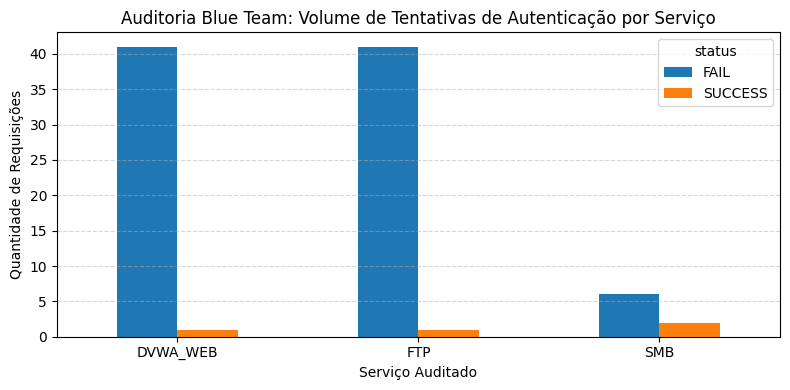


=== [TESTE DE MITIGAÇÃO] Ativando Política de Account Lockout (Máx. 3 Falhas) ===
Tentativa 1 (senha='errada_1') -> HTTP 401: 530 Login incorrect
Tentativa 2 (senha='errada_2') -> HTTP 401: 530 Login incorrect
Tentativa 3 (senha='errada_3') -> HTTP 401: 530 Login incorrect
Tentativa 4 (senha='errada_4') -> HTTP 429: 429 Too Many Requests - Conta temporariamente bloqueada
Tentativa 5 (senha='msfadmin') -> HTTP 429: 429 Too Many Requests - Conta temporariamente bloqueada


In [13]:
# ==============================================================================
# CÉLULA 6: BLUE TEAM — ANÁLISE DE LOGS (SIEM) E VALIDAÇÃO DE BLOQUEIO (LOCKOUT)
# ==============================================================================

df_logs = pd.DataFrame(LOGS_AUDITORIA)
print(f"[+] Total de eventos capturados pelo servidor de auditoria: {len(df_logs)} requisições\n")

# Resumo estatístico por Serviço e Status
resumo_ataques = df_logs.groupby(["servico", "status"]).size().unstack(fill_value=0)
display(resumo_ataques)

# Visualização gráfica das tentativas por serviço
ax = resumo_ataques.plot(
    kind="bar",
    figsize=(8, 4),
    title="Auditoria Blue Team: Volume de Tentativas de Autenticação por Serviço"
)
plt.xlabel("Serviço Auditado")
plt.ylabel("Quantidade de Requisições")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# VALIDAÇÃO DE MITIGAÇÃO: Ativando o Bloqueio Automático (Account Lockout)
# ------------------------------------------------------------------------------
print("\n=== [TESTE DE MITIGAÇÃO] Ativando Política de Account Lockout (Máx. 3 Falhas) ===")
CONTROLE_BLOQUEIO["modo_defensivo_ativo"] = True
CONTROLE_BLOQUEIO["falhas_por_conta"].clear()

for tentativa in range(1, 6):
    senha_teste = "msfadmin" if tentativa == 5 else f"errada_{tentativa}"
    r = requests.get(f"{URL_BASE}/ftp-sim", auth=("msfadmin", senha_teste))
    print(f"Tentativa {tentativa} (senha='{senha_teste}') -> HTTP {r.status_code}: {r.text}")